
# TCC II — Análise de Sentimentos em Textos Informais

## Objetivo

Este notebook apresenta os experimentos do Trabalho de Conclusão de Curso II, cujo objetivo é investigar o impacto de diferentes configurações de pré-processamento textual sobre o desempenho de modelos de classificação de sentimentos em português.

A investigação dá continuidade ao TCC I, no qual foram observadas diferenças de desempenho entre textos brutos e textos submetidos a técnicas tradicionais de pré-processamento.

## Modelos avaliados

- Regressão Logística
- Support Vector Machine (SVM)
- Long Short-Term Memory (LSTM)
- BERTimbau

## Condições experimentais

1. Texto Bruto
2. Limpeza Básica
3. Pipeline Completo
4. Sem Emoticons

A principal métrica de avaliação é o **F1-Score Macro**, utilizando-se também a acurácia como medida complementar.

## Organização dos experimentos

O notebook contempla:

1. Preparação e auditoria do corpus;
2. Divisão entre treinamento e teste;
3. Pré-processamento textual;
4. Classificadores tradicionais;
5. Rede neural LSTM;
6. BERTimbau;
7. Estudo de ablação;
8. Consolidação dos resultados;
9. Análise qualitativa dos erros.

As etapas utilizam divisões experimentais controladas. O BERTimbau é avaliado em uma amostra estratificada menor, devido às limitações computacionais, o que deve ser considerado na interpretação das comparações.

## Reprodutibilidade

Os experimentos utilizam sementes aleatórias definidas e mantêm a separação entre treinamento e teste. As configurações específicas de cada modelo são documentadas nas respectivas seções.


In [4]:
# ============================================================
# 0. PREPARAÇÃO DO AMBIENTE
# ============================================================

# Instalação das bibliotecas necessárias (incluindo transformers para o BERTimbau)
!pip install pandas numpy scikit-learn tensorflow keras matplotlib seaborn transformers datasets accelerate -q

import re
import html
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import importlib

import nltk
import nltk.data
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('rslp', quiet=True)

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import RSLPStemmer

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

import tensorflow as tf
# Impede que o TensorFlow aloque 100% da VRAM da GPU T4 sozinho
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SpatialDropout1D, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("✓ Ambiente configurado com sucesso para o TCC II!")

✓ Ambiente configurado com sucesso para o TCC II!


# 1. Auditoria e preparação do corpus

O que ela faz?

Essa célula verifica as características iniciais do dataset e prepara o corpus para os experimentos.

Entre as verificações estão:
- quantidade de registros;
- classes existentes;
- distribuição das classes;
- valores ausentes;
- textos duplicados;
- textos com rótulos conflitantes;
- características gerais dos textos;
- características relacionadas aos emoticons e demais elementos presentes no corpus.

Depois dessa auditoria, o corpus pode ser definido de forma consistente para os experimentos.

Por que essa célula existe?

Porque antes de treinar qualquer modelo precisamos saber exatamente com que dados estamos trabalhando.

Um resultado de classificação não pode ser interpretado corretamente sem conhecer a composição do corpus. Por exemplo, se uma classe tivesse muito mais exemplos que outra, uma métrica elevada poderia ser parcialmente explicada pelo desbalanceamento.

No nosso caso, a auditoria mostrou algo particularmente importante: as três classes já estão praticamente perfeitamente equilibradas.

Também foram encontrados registros duplicados e um caso de texto associado a rótulos diferentes.

O que ela adiciona à pesquisa?

Ela fornece uma caracterização empírica do corpus e permite justificar as decisões tomadas antes do treinamento.

Além disso, evita uma decisão metodológica que seria inadequada neste dataset: realizar um balanceamento artificial sem necessidade.

Isso é especialmente relevante porque o TCC I havia planejado “expandir e balancear” o corpus como uma etapa do TCC II. A auditoria permite mostrar que essa hipótese inicial foi reavaliada a partir dos dados reais, em vez de simplesmente aplicar uma técnica de balanceamento por obrigação.

Em termos de pesquisa:

A Célula 1 responde: “Os dados estão adequados e quais características do corpus podem influenciar os resultados?”

In [5]:
# ============================================================
# 1. CARREGAMENTO E AUDITORIA DO DATASET
# ============================================================

from google.colab import files
import pandas as pd
import numpy as np

print("Faça o upload do arquivo Train3Classes.csv...")
uploaded = files.upload()

arquivo_nome = list(uploaded.keys())[0]

# Dataset utiliza ';' como separador
df_raw = pd.read_csv(
    arquivo_nome,
    sep=';',
    encoding='utf-8',
    on_bad_lines='skip'
)

print("\n" + "="*60)
print("AUDITORIA INICIAL DO DATASET")
print("="*60)

print(f"Quantidade de registros: {len(df_raw):,}")
print(f"Quantidade de colunas: {len(df_raw.columns)}")
print(f"Colunas: {list(df_raw.columns)}")

# ------------------------------------------------------------
# Valores ausentes
# ------------------------------------------------------------

print("\nValores ausentes:")
display(df_raw.isna().sum().to_frame("Quantidade"))

# ------------------------------------------------------------
# Distribuição original das classes (Teste 1)
# ------------------------------------------------------------

dist_original = (
    df_raw['sentiment']
    .value_counts()
    .sort_index()
    .to_frame('Quantidade')
)

dist_original['Percentual (%)'] = (
    dist_original['Quantidade'] / len(df_raw) * 100
).round(3)

print("\nDistribuição original das classes:")
display(dist_original)

# ------------------------------------------------------------
# Duplicatas exatas de tweet
# ------------------------------------------------------------

duplicados = df_raw[df_raw.duplicated(
    subset='tweet_text',
    keep=False
)].copy()

print(f"\nRegistros envolvidos em duplicatas: {len(duplicados):,}")
print(
    f"Textos distintos que aparecem mais de uma vez: "
    f"{duplicados['tweet_text'].nunique():,}"
)

# ------------------------------------------------------------
# Conflitos de rótulo
# ------------------------------------------------------------

rotulos_por_texto = (
    df_raw.groupby('tweet_text')['sentiment']
    .nunique()
)

textos_conflitantes = set(
    rotulos_por_texto[rotulos_por_texto > 1].index
)

print(
    f"\nTextos com conflito de rótulo: "
    f"{len(textos_conflitantes):,}"
)

if textos_conflitantes:
    print("\nExemplos de conflitos:")
    cols_exibir = [c for c in ['id', 'tweet_text', 'sentiment', 'query_used'] if c in df_raw.columns]
    display(
        df_raw[
            df_raw['tweet_text'].isin(textos_conflitantes)
        ][cols_exibir].head(20)
    )

# ------------------------------------------------------------
# Relação entre query_used e sentimento (Teste 2)
# ------------------------------------------------------------

if 'query_used' in df_raw.columns:
    print("\nDistribuição de query_used por sentimento:")
    query_sentimento = pd.crosstab(
        df_raw['query_used'],
        df_raw['sentiment']
    )

    display(
        query_sentimento
        .sort_values(
            by=list(query_sentimento.columns),
            ascending=False
        )
        .head(20)
    )

# ------------------------------------------------------------
# Presença de marcadores emocionais (Geral e Teste 3 por Classe)
# ------------------------------------------------------------

texto = df_raw['tweet_text'].fillna('').astype(str)

padroes_emoticons = {
    ':)' : r':\)',
    ':(' : r':\(',
    ':D' : r':D',
    ';)' : r';\)',
    'XD' : r'\bXD\b'
}

print("\nPresença de marcadores emocionais (Geral):")

resumo_emo_classe = pd.DataFrame(index=sorted(df_raw['sentiment'].dropna().unique()))
resumo_emo_classe.index.name = 'Classe (sentiment)'

for nome, padrao in padroes_emoticons.items():
    mascara = texto.str.contains(
        padrao,
        regex=True,
        na=False
    )

    quantidade = mascara.sum()

    print(
        f"{nome:>3}: "
        f"{quantidade:,} registros "
        f"({quantidade / len(df_raw) * 100:.2f}%)"
    )

    # Cálculo percentual dentro de cada classe (Teste 3)
    pct_por_classe = mascara.groupby(df_raw['sentiment']).mean() * 100
    resumo_emo_classe[f'% com {nome}'] = pct_por_classe.round(2)

print("\nPresença percentual de marcadores emocionais POR CLASSE (Teste 3):")
display(resumo_emo_classe)

# ============================================================
# LIMPEZA PARA O CORPUS EXPERIMENTAL
# ============================================================

print("\n" + "="*60)
print("CONSTRUÇÃO DO CORPUS EXPERIMENTAL")
print("="*60)

df = df_raw.dropna(subset=['tweet_text', 'sentiment']).copy()
df = df[df['tweet_text'].astype(str).str.strip() != ''].copy()

# 1. Remover textos que possuem conflito de rótulo
if textos_conflitantes:
    df = df[
        ~df['tweet_text'].isin(textos_conflitantes)
    ].copy()

    print(
        f"Removidos por conflito de rótulo: "
        f"{len(textos_conflitantes)} texto(s) distintos"
    )

# 2. Remover duplicatas exatas de texto
antes_dedup = len(df)

df = df.drop_duplicates(
    subset='tweet_text',
    keep='first'
).reset_index(drop=True)

removidos_dedup = antes_dedup - len(df)

print(
    f"Duplicatas exatas removidas: "
    f"{removidos_dedup:,}"
)

# 3. Estatísticas de comprimento dos textos (Auditoria 3.X)
df['len_chars'] = df['tweet_text'].astype(str).str.len()
df['len_words'] = df['tweet_text'].astype(str).str.split().str.len()
print("\nComprimento dos textos no Corpus Experimental (Caracteres e Palavras):")
display(df.groupby('sentiment')[['len_chars', 'len_words']].agg(['mean', 'median', 'std']).round(2))

print(
    f"\nTamanho final do corpus experimental: "
    f"{len(df):,}"
)

# ------------------------------------------------------------
# Distribuição final das classes
# ------------------------------------------------------------

dist_final = (
    df['sentiment']
    .value_counts()
    .sort_index()
    .to_frame('Quantidade')
)

dist_final['Percentual (%)'] = (
    dist_final['Quantidade'] / len(df) * 100
).round(3)

print("\nDistribuição final das classes:")
display(dist_final)

print("\nVerificação de duplicatas restantes:")
print(
    "Duplicatas:",
    df.duplicated('tweet_text').sum()
)

print("\n✓ Auditoria concluída.")

Faça o upload do arquivo Train3Classes.csv...


Saving Train3Classes.csv to Train3Classes.csv

AUDITORIA INICIAL DO DATASET
Quantidade de registros: 100,000
Quantidade de colunas: 5
Colunas: ['id', 'tweet_text', 'tweet_date', 'sentiment', 'query_used']

Valores ausentes:


,Quantidade
id,0
tweet_text,0
tweet_date,0
sentiment,0
query_used,0



Distribuição original das classes:


,Quantidade,Percentual (%)
sentiment,,
0,33333,33.333
1,33334,33.334
2,33333,33.333


...


CONSTRUÇÃO DO CORPUS EXPERIMENTAL
Removidos por conflito de rótulo: 1 texto(s) distintos
Duplicatas exatas removidas: 896

Comprimento dos textos no Corpus Experimental (Caracteres e Palavras):


len_chars               len_words              
               mean median    std      mean median    std
sentiment                                                
0             73.24   56.0  53.35     13.17   10.0   9.99
1             90.28   70.0  65.12     15.44   12.0  11.45
2            128.76  112.0  55.69     16.48   14.0   7.86


Tamanho final do corpus experimental: 99,102

Distribuição final das classes:


,Quantidade,Percentual (%)
sentiment,,
0,33057,33.357
1,32900,33.198
2,33145,33.445



Verificação de duplicatas restantes:
Duplicatas: 0

✓ Auditoria concluída.


# 2. Divisão entre treinamento e teste
O que ela faz?

Divide o corpus em:
- 80% para treinamento
- 20% para teste
utilizando divisão estratificada e uma semente fixa (SEED = 42).

Além disso, são verificadas duas condições:
1. não existem índices compartilhados entre treino e teste;
2. não existem textos duplicados entre treino e teste.
Por que essa célula existe?
Porque precisamos garantir que os modelos sejam avaliados em dados que não foram utilizados durante seu treinamento.

Se um mesmo tweet aparecesse no treinamento e no teste, o modelo poderia simplesmente aprender características daquela instância, produzindo uma estimativa artificialmente otimista de desempenho.

A estratificação também garante que as proporções das três classes sejam preservadas nos dois conjuntos.

O que ela adiciona à pesquisa?

Ela cria uma base experimental controlada e reproduzível.

Depois que essa divisão é estabelecida, todos os modelos podem ser comparados usando exatamente o mesmo conjunto de treinamento e exatamente o mesmo conjunto de teste.

Isso é essencial para o estudo de ablação.

Se uma configuração obtivesse F1 = 0,82 e outra F1 = 0,84, poderíamos atribuir a diferença com muito mais segurança à representação textual/processamento, e não a uma mudança na amostra de teste.

Em termos de pesquisa:

A Célula 2 responde:
“Estamos comparando os modelos sob as mesmas condições experimentais?”

In [6]:
# ============================================================
# 2. DEFINIÇÃO DO SPLIT EXPERIMENTAL
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

SEED = 42

# ------------------------------------------------------------
# Codificação dos rótulos
# ------------------------------------------------------------

label_encoder = LabelEncoder()

df['sentiment_enc'] = label_encoder.fit_transform(
    df['sentiment']
)

print("Mapeamento das classes:")

for classe_original, classe_encoded in zip(
    label_encoder.classes_,
    range(len(label_encoder.classes_))
):
    print(
        f"  {classe_original} → {classe_encoded}"
    )

# ------------------------------------------------------------
# Índices do corpus
# ------------------------------------------------------------

indices = np.arange(len(df))

idx_tr, idx_te = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=df['sentiment_enc']
)

# ------------------------------------------------------------
# Construção dos conjuntos
# ------------------------------------------------------------

df_train = df.iloc[idx_tr].copy()
df_test = df.iloc[idx_te].copy()

print("\n" + "="*60)
print("SPLIT EXPERIMENTAL")
print("="*60)

print(f"Total:      {len(df):,}")
print(f"Treino:     {len(df_train):,}")
print(f"Teste:      {len(df_test):,}")

print("\nDistribuição no treino:")

dist_train = (
    df_train['sentiment']
    .value_counts()
    .sort_index()
    .to_frame('Quantidade')
)

dist_train['Percentual (%)'] = (
    dist_train['Quantidade']
    / len(df_train)
    * 100
).round(3)

display(dist_train)

print("\nDistribuição no teste:")

dist_test = (
    df_test['sentiment']
    .value_counts()
    .sort_index()
    .to_frame('Quantidade')
)

dist_test['Percentual (%)'] = (
    dist_test['Quantidade']
    / len(df_test)
    * 100
).round(3)

display(dist_test)

# ------------------------------------------------------------
# Verificações
# ------------------------------------------------------------

assert len(set(idx_tr) & set(idx_te)) == 0

assert (
    df_train['tweet_text']
    .isin(df_test['tweet_text'])
    .sum()
    == 0
)

print("\n✓ Não existem índices compartilhados entre treino e teste.")
print("✓ Não existem tweets duplicados entre treino e teste.")
print("✓ Split estratificado criado com sucesso.")

Mapeamento das classes:
  0 → 0
  1 → 1
  2 → 2

SPLIT EXPERIMENTAL
Total:      99,102
Treino:     79,281
Teste:      19,821

Distribuição no treino:


,Quantidade,Percentual (%)
sentiment,,
0,26445,33.356
1,26320,33.198
2,26516,33.446



Distribuição no teste:


,Quantidade,Percentual (%)
sentiment,,
0,6612,33.359
1,6580,33.197
2,6629,33.444



✓ Não existem índices compartilhados entre treino e teste.
✓ Não existem tweets duplicados entre treino e teste.
✓ Split estratificado criado com sucesso.


# 3. Pré-processamento e criação das representações textuais

O que ela faz?

Ela cria diferentes representações do mesmo corpus.

Entre elas:
- texto original;
- texto com limpeza básica;
- texto com remoção de stopwords e stemming;
- texto sem emoticons, utilizado como condição diagnóstica.

A limpeza básica envolve operações como:
- normalização para minúsculas;
- remoção de URLs;
- remoção de menções;
- preservação do conteúdo das hashtags;
- redução de alongamentos;
- normalização de caracteres.

Já o pipeline completo adiciona:
- remoção de stopwords;
- stemming com RSLP.

Por que essa célula existe?

Porque o pré-processamento é justamente uma das variáveis investigadas pelo TCC.

O TCC I já havia demonstrado que o pipeline tradicional prejudicou os modelos e levantado a hipótese de que elementos considerados “ruído” podem carregar informação semântica e emocional em textos de redes sociais.

Portanto, não basta comparar:
“texto antes” × “texto depois”.

Precisamos saber qual transformação provocou a mudança.

O que ela adiciona à pesquisa?

Ela cria as condições necessárias para o estudo de ablação.

A ideia é retirar ou adicionar etapas individualmente e observar o impacto no desempenho.

Isso permite transformar uma observação como:
“O pré-processamento piorou o modelo.”

em uma conclusão muito mais interessante:
“Determinadas etapas do pré-processamento foram responsáveis por parte da perda de desempenho, enquanto outras tiveram impacto menor.”

Essa é justamente a lógica que já estava presente no TCC I, que identificou a remoção de stopwords como o componente de maior impacto negativo.     

Em termos de pesquisa:

A Célula 3 responde:
“Quais características do texto estão sendo preservadas ou removidas em cada configuração experimental?”

In [7]:
# ============================================================
# 3. PRÉ-PROCESSAMENTO TEXTUAL
# ============================================================

import re
import html
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import RSLPStemmer

# Garante que os recursos do NLTK estão baixados no Colab
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('rslp', quiet=True)

# ------------------------------------------------------------
# Stopwords (Preservando negações com e sem acento)
# ------------------------------------------------------------

NEGACOES_PT = {
    'não',
    'nao',
    'nunca',
    'jamais',
    'tampouco',
    'nem'
}

STOPWORDS_PT = (
    set(stopwords.words('portuguese'))
    - NEGACOES_PT
)

stemmer_pt = RSLPStemmer()

# ------------------------------------------------------------
# Expressões regulares
# ------------------------------------------------------------

RE_URL = re.compile(
    r'https?://\S+|www\.\S+'
)

RE_MENCAO = re.compile(
    r'@\w+'
)

RE_HASHTAG = re.compile(
    r'#(\w+)'
)

RE_REP = re.compile(
    r'(.)\1{2,}'
)

RE_NAO_ALFA = re.compile(
    r'[^a-zA-ZáàâãéèêíïóôõöúçñÁÀÂÃÉÈÊÍÏÓÔÕÖÚÇÑ\s]'
)

RE_ESP = re.compile(
    r'\s+'
)

# ------------------------------------------------------------
# Marcadores emocionais explícitos (Protegendo links http/https)
# ------------------------------------------------------------

RE_EMOTICON = re.compile(
    r'(?<!http)(?<!https)'
    r'(?:[:;=][-^]?[)(/\\|DPdp]+|8[-^]?[)(\\|DPdp]+)'
)

# ------------------------------------------------------------
# Limpeza básica
# ------------------------------------------------------------

def limpar_texto_pt(texto):

    if not isinstance(texto, str):
        return ""

    texto = html.unescape(texto).lower()

    texto = RE_URL.sub(' ', texto)

    texto = RE_MENCAO.sub(' ', texto)

    # Preserva o conteúdo textual da hashtag
    texto = RE_HASHTAG.sub(
        r' \1 ',
        texto
    )

    # Reduz alongamentos:
    # "muitooooo" → "muitoo"
    texto = RE_REP.sub(
        r'\1\1',
        texto
    )

    texto = RE_NAO_ALFA.sub(
        ' ',
        texto
    )

    return RE_ESP.sub(
        ' ',
        texto
    ).strip()


# ------------------------------------------------------------
# Remoção apenas dos marcadores emocionais
# ------------------------------------------------------------

def remover_emoticons(texto):

    if not isinstance(texto, str):
        return ""

    texto = RE_EMOTICON.sub(
        ' ',
        texto
    )

    return RE_ESP.sub(
        ' ',
        texto
    ).strip()


# ------------------------------------------------------------
# Pipeline completo
# ------------------------------------------------------------

def aplicar_pipeline_pt(
    base_limpa,
    usar_stopwords=True,
    usar_stemming=True
):

    tokens = word_tokenize(
        base_limpa,
        language='portuguese'
    )

    if usar_stopwords:

        tokens = [
            t for t in tokens
            if t not in STOPWORDS_PT
            and len(t) > 2
        ]

    if usar_stemming:

        tokens = [
            stemmer_pt.stem(t)
            for t in tokens
        ]

    return ' '.join(tokens)


# ============================================================
# GERAÇÃO DAS REPRESENTAÇÕES
# ============================================================

print(
    "Iniciando pré-processamento textual..."
)

# Texto com limpeza básica
df['_base'] = (
    df['tweet_text']
    .astype(str)
    .map(limpar_texto_pt)
)

# Texto completo: stopwords + stemming
df['text_limpo'] = (
    df['_base']
    .map(
        lambda b: aplicar_pipeline_pt(
            b,
            usar_stopwords=True,
            usar_stemming=True
        )
    )
)

# Texto bruto sem emoticons explícitos
df['texto_sem_emoticons'] = (
    df['tweet_text']
    .astype(str)
    .map(remover_emoticons)
)

print("✓ Representações textuais criadas.")

display(
    df[
        [
            'tweet_text',
            'texto_sem_emoticons',
            'text_limpo',
            'sentiment'
        ]
    ].head(10)
)

Iniciando pré-processamento textual...
✓ Representações textuais criadas.


,tweet_text,texto_sem_emoticons,text_limpo,sentiment
0,@Laranjito76 A pessoa certa para isso seria o ...,@Laranjito76 A pessoa certa para isso seria o ...,pesso cert val azeved,1
1,"@behin_d_curtain Para mim, é precisamente o co...","@behin_d_curtain Para mim, é precisamente o co...",mim precis contr vem chuv vem boa dispos,1
2,Vou fazer um video hoje... estou pensando em f...,Vou fazer um video hoje... estou pensando em f...,vou faz vide hoj pens fal pouc sobr nov met cs...,1
3,"aaaaaaaa amei tanto essas polaroids, nem sei e...","aaaaaaaa amei tanto essas polaroids, nem sei e...",ame tant polaroid nem sei express quant apaixo...,1
4,Valoriza o coração do menininho que vc tem. El...,Valoriza o coração do menininho que vc tem. El...,valoriz coraçã menin difer faç sorr ter cert d...,1
5,@KingJokerLeto mas amiga eu to aqui ainda :),@KingJokerLeto mas amiga eu to aqui ainda,amig aqu aind,1
6,"@RivasJairo Bravo, Jairo!!! :)))","@RivasJairo Bravo, Jairo!!!",brav jair,1
7,@inquilinasls @Spotify socorro ksoaksosks acho...,@inquilinasls @Spotify socorro ksoaksosks acho...,socorr ksoaksosk ach porqu us caix som,1
8,"@chimekarlla gosto muito de fazenda :) , mas m...","@chimekarlla gosto muito de fazenda , mas morr...",gost fazend morr med gal,1
9,Amanha vou ver venom :D,Amanha vou ver venom,amanh vou ver venom,1


## 3.1. Atualização dos conjuntos de treino e teste
Essa célula parece pequena, mas é metodologicamente importante.

O que ela faz?

Depois que a Célula 3 cria novas colunas no df, ela recria:
- df_train
- df_test

utilizando os mesmos índices definidos na Célula 2.

Por que ela existe?

Porque o treinamento/teste foi definido antes das novas representações textuais serem criadas.

Então precisamos atualizar os DataFrames para que eles contenham:
- tweet_text;
- _base;
- text_limpo;
- texto_sem_emoticons;
- demais informações necessárias.
Mas sem realizar uma nova divisão.

O que ela adiciona à pesquisa?

Garante que todas as representações textuais sejam avaliadas sobre exatamente os mesmos exemplos de treino e teste.

Isso preserva a validade do experimento.

É importante destacar para o orientador:
Essa célula não cria uma nova amostra. Ela apenas atualiza os conjuntos previamente definidos.

Em termos de pesquisa:

A Célula 3.1 responde:
“Todas as condições experimentais continuam utilizando exatamente a mesma divisão de dados?”

In [8]:
# ============================================================
# 3.1. ATUALIZAÇÃO DOS CONJUNTOS DE TREINO E TESTE
# ============================================================

# Recria treino e teste a partir do df já pré-processado

df_train = df.iloc[idx_tr].copy()
df_test = df.iloc[idx_te].copy()

print("✓ Conjuntos de treino e teste atualizados.")
print(f"Treino: {len(df_train):,}")
print(f"Teste:  {len(df_test):,}")

print("\nColunas disponíveis:")
print(df_train.columns.tolist())

✓ Conjuntos de treino e teste atualizados.
Treino: 79,281
Teste:  19,821

Colunas disponíveis:
['id', 'tweet_text', 'tweet_date', 'sentiment', 'query_used', 'len_chars', 'len_words', 'sentiment_enc', '_base', 'text_limpo', 'texto_sem_emoticons']



# 4. Modelos Tradicionais — Regressão Logística e SVM

Esta seção apresenta o treinamento e a avaliação dos classificadores tradicionais de Regressão Logística e Support Vector Machine (SVM), utilizados como modelos de referência (*baselines*).

Os textos são representados numericamente por meio de TF-IDF, considerando unigramas e bigramas.

Cada modelo é avaliado nas quatro condições experimentais:

- Texto Bruto
- Limpeza Básica
- Pipeline Completo
- Sem Emoticons

A avaliação utiliza a mesma divisão entre treinamento e teste, adotando o F1-Score Macro como métrica principal e a acurácia como métrica complementar.

O objetivo é investigar como diferentes configurações de pré-processamento afetam o desempenho dos classificadores tradicionais.


In [ ]:

# ============================================================
# 4.1. CONFIGURAÇÃO E FUNÇÃO DE AVALIAÇÃO
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report
)

import pandas as pd
import numpy as np
import time

# ------------------------------------------------------------
# Configuração
# ------------------------------------------------------------

MAX_FEATURES = 50000

CONDICOES = {
    'Texto Bruto': 'tweet_text',
    'Limpeza Básica': '_base',
    'Pipeline Completo': 'text_limpo',
    'Sem Emoticons': 'texto_sem_emoticons'
}

# ------------------------------------------------------------
# Função de avaliação
# ------------------------------------------------------------

def avaliar_baseline(
    nome_modelo,
    nome_condicao,
    coluna_texto
):

    print("\n" + "=" * 70)
    print(f"{nome_modelo} — {nome_condicao}")
    print("=" * 70)

    # --------------------------------------------------------
    # Seleção dos dados
    # --------------------------------------------------------

    textos_treino = (
        df_train[coluna_texto]
        .fillna('')
        .astype(str)
    )

    textos_teste = (
        df_test[coluna_texto]
        .fillna('')
        .astype(str)
    )

    y_train = df_train['sentiment_enc']
    y_test = df_test['sentiment_enc']

    # --------------------------------------------------------
    # Representação TF-IDF
    # --------------------------------------------------------

    inicio = time.time()

    vectorizer = TfidfVectorizer(
        max_features=MAX_FEATURES,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )

    X_train = vectorizer.fit_transform(
        textos_treino
    )

    X_test = vectorizer.transform(
        textos_teste
    )

    print(
        f"TF-IDF: "
        f"{X_train.shape[0]:,} x "
        f"{X_train.shape[1]:,}"
    )

    # --------------------------------------------------------
    # Seleção do modelo
    # --------------------------------------------------------

    if nome_modelo == 'Regressão Logística':

        modelo = LogisticRegression(
            max_iter=1000,
            random_state=SEED,
            n_jobs=-1
        )

    elif nome_modelo == 'SVM':

        modelo = LinearSVC(
            random_state=SEED
        )

    else:

        raise ValueError(
            f"Modelo desconhecido: {nome_modelo}"
        )

    # --------------------------------------------------------
    # Treinamento e predição
    # --------------------------------------------------------

    modelo.fit(
        X_train,
        y_train
    )

    y_pred = modelo.predict(
        X_test
    )

    tempo = time.time() - inicio

    # --------------------------------------------------------
    # Métricas
    # --------------------------------------------------------

    f1_macro = f1_score(
        y_test,
        y_pred,
        average='macro'
    )

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    print(f"Accuracy: {accuracy:.4f}")
    print(f"F1 Macro: {f1_macro:.4f}")
    print(f"Tempo: {tempo:.2f}s")

    print("\nClassification Report:")

    print(
        classification_report(
            y_test,
            y_pred,
            digits=4
        )
    )

    # --------------------------------------------------------
    # Registro dos resultados
    # --------------------------------------------------------

    resultados_baseline.append({
        'Modelo': nome_modelo,
        'Condição': nome_condicao,
        'F1 Macro': f1_macro,
        'Accuracy': accuracy,
        'Tempo (s)': tempo
    })


print("✓ Configuração e função de avaliação definidas.")


✓ Configuração e função de avaliação definidas.


In [ ]:

# ============================================================
# 4.2. EXECUÇÃO E RESULTADOS DOS MODELOS TRADICIONAIS
# ============================================================

# Inicialização dos resultados
resultados_baseline = []

# ------------------------------------------------------------
# Execução das quatro condições
# ------------------------------------------------------------

for nome_condicao, coluna in CONDICOES.items():

    avaliar_baseline(
        'Regressão Logística',
        nome_condicao,
        coluna
    )

    avaliar_baseline(
        'SVM',
        nome_condicao,
        coluna
    )

# ------------------------------------------------------------
# Consolidação dos resultados
# ------------------------------------------------------------

resultados_baseline_df = pd.DataFrame(
    resultados_baseline
)

# Validação
assert len(resultados_baseline_df) == 8

assert not resultados_baseline_df.duplicated(
    ['Modelo', 'Condição']
).any()

# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESULTADOS — MODELOS TRADICIONAIS")
print("=" * 70)

display(
    resultados_baseline_df
    .sort_values(
        'F1 Macro',
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n✓ Experimentos dos modelos tradicionais concluídos.")



# 5. Rede Neural LSTM

Esta seção apresenta o treinamento e a avaliação de uma rede neural recorrente Long Short-Term Memory (LSTM), utilizada para investigar o impacto do pré-processamento textual em uma arquitetura que considera a sequência dos tokens.

A LSTM é avaliada nas mesmas quatro condições experimentais utilizadas pelos classificadores tradicionais:

- Texto Bruto
- Limpeza Básica
- Pipeline Completo
- Sem Emoticons

Os textos são convertidos em sequências numéricas por meio do Tokenizer do Keras e padronizados com padding.

A arquitetura utiliza uma camada Embedding, uma camada LSTM com 128 unidades, uma camada Dense com 64 neurônios, Dropout e uma camada de saída Softmax com três classes.

O treinamento utiliza o otimizador Adam, a função de perda sparse categorical crossentropy e EarlyStopping para controlar o número de épocas.

A avaliação utiliza F1-Score Macro e Accuracy, mantendo a mesma divisão experimental dos classificadores tradicionais.

**Observação metodológica:** o Tokenizer padrão do Keras aplica filtros de pontuação, podendo remover caracteres que compõem emoticons. Portanto, a representação denominada Texto Bruto não preserva necessariamente todos os símbolos do texto original.


In [ ]:

# ============================================================
# 5.1. CONFIGURAÇÃO E FUNÇÃO DE AVALIAÇÃO — LSTM
# ============================================================

import numpy as np
import pandas as pd
import time
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, LSTM, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report
)

# ------------------------------------------------------------
# Configuração experimental
# ------------------------------------------------------------

SEED_LSTM = SEED

np.random.seed(SEED_LSTM)
tf.random.set_seed(SEED_LSTM)

MAX_VOCAB = 30000
MAX_LEN = 100
EMBED_DIM = 128

BATCH_SIZE = 128
EPOCHS = 10

CONDICOES_LSTM = {
    'Texto Bruto': 'tweet_text',
    'Limpeza Básica': '_base',
    'Pipeline Completo': 'text_limpo',
    'Sem Emoticons': 'texto_sem_emoticons'
}

# ------------------------------------------------------------
# Função de avaliação
# ------------------------------------------------------------

def avaliar_lstm(nome_condicao, coluna_texto):

    print("\n" + "=" * 70)
    print(f"LSTM — {nome_condicao}")
    print("=" * 70)

    # Dados
    textos_treino = (
        df_train[coluna_texto]
        .fillna('')
        .astype(str)
        .tolist()
    )

    textos_teste = (
        df_test[coluna_texto]
        .fillna('')
        .astype(str)
        .tolist()
    )

    y_train = df_train['sentiment_enc'].values
    y_test = df_test['sentiment_enc'].values

    inicio = time.time()

    # --------------------------------------------------------
    # Tokenização
    # --------------------------------------------------------

    tokenizer = Tokenizer(
        num_words=MAX_VOCAB,
        oov_token='<OOV>'
    )

    # Vocabulário aprendido somente no treino
    tokenizer.fit_on_texts(textos_treino)

    X_train_seq = tokenizer.texts_to_sequences(
        textos_treino
    )

    X_test_seq = tokenizer.texts_to_sequences(
        textos_teste
    )

    # --------------------------------------------------------
    # Padding
    # --------------------------------------------------------

    X_train = pad_sequences(
        X_train_seq,
        maxlen=MAX_LEN,
        padding='post',
        truncating='post'
    )

    X_test = pad_sequences(
        X_test_seq,
        maxlen=MAX_LEN,
        padding='post',
        truncating='post'
    )

    vocab_size = min(
        MAX_VOCAB,
        len(tokenizer.word_index) + 1
    )

    print(f"Vocabulário: {vocab_size:,}")
    print(f"Treino: {X_train.shape}")
    print(f"Teste:  {X_test.shape}")

    # --------------------------------------------------------
    # Arquitetura LSTM
    # --------------------------------------------------------

    modelo = Sequential([
        Embedding(
            input_dim=vocab_size,
            output_dim=EMBED_DIM,
            mask_zero=True
        ),

        LSTM(
            128,
            dropout=0.2,
            use_cudnn=False
        ),

        Dense(
            64,
            activation='relu'
        ),

        Dropout(0.3),

        Dense(
            3,
            activation='softmax'
        )
    ])

    modelo.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # --------------------------------------------------------
    # Early Stopping
    # --------------------------------------------------------

    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=2,
        restore_best_weights=True
    )

    # --------------------------------------------------------
    # Treinamento
    # --------------------------------------------------------

    history = modelo.fit(
        X_train,
        y_train,
        validation_split=0.1,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        verbose=1
    )

    # --------------------------------------------------------
    # Predição
    # --------------------------------------------------------

    y_prob = modelo.predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=1
    )

    y_pred = np.argmax(
        y_prob,
        axis=1
    )

    tempo = time.time() - inicio

    # --------------------------------------------------------
    # Métricas
    # --------------------------------------------------------

    f1_macro = f1_score(
        y_test,
        y_pred,
        average='macro'
    )

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    print("\n" + "-" * 70)
    print(f"RESULTADOS — LSTM / {nome_condicao}")
    print("-" * 70)

    print(f"Accuracy: {accuracy:.4f}")
    print(f"F1 Macro: {f1_macro:.4f}")
    print(f"Tempo: {tempo:.2f}s")

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            digits=4
        )
    )

    # --------------------------------------------------------
    # Registro dos resultados
    # --------------------------------------------------------

    resultados_lstm.append({
        'Modelo': 'LSTM',
        'Condição': nome_condicao,
        'F1 Macro': f1_macro,
        'Accuracy': accuracy,
        'Tempo (s)': tempo
    })

    return {
        'modelo': modelo,
        'tokenizer': tokenizer,
        'history': history,
        'y_pred': y_pred,
        'y_prob': y_prob
    }


print("✓ Configuração e função da LSTM definidas.")


✓ Configuração e função da LSTM definidas.


In [ ]:

# ============================================================
# 5.2. EXECUÇÃO E RESULTADOS — LSTM
# ============================================================

# Inicialização
resultados_lstm = []
modelos_lstm = {}

# ------------------------------------------------------------
# Execução das quatro condições
# ------------------------------------------------------------

for nome_condicao, coluna in CONDICOES_LSTM.items():

    modelos_lstm[nome_condicao] = avaliar_lstm(
        nome_condicao,
        coluna
    )

# ------------------------------------------------------------
# Consolidação dos resultados
# ------------------------------------------------------------

resultados_lstm_df = pd.DataFrame(
    resultados_lstm
)

# Validação
assert len(resultados_lstm_df) == 4

assert not resultados_lstm_df.duplicated(
    ['Modelo', 'Condição']
).any()

# ------------------------------------------------------------
# Apresentação
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESULTADOS — LSTM")
print("=" * 70)

display(
    resultados_lstm_df
    .sort_values(
        'F1 Macro',
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n✓ Experimentos da LSTM concluídos.")



# 6. BERTimbau — Classificação de Sentimentos

Esta seção apresenta o treinamento e a avaliação do BERTimbau, modelo baseado na arquitetura Transformer e pré-treinado para a língua portuguesa.

Foi utilizado o modelo `neuralmind/bert-base-portuguese-cased`, adaptado para a tarefa de classificação de sentimentos em três classes.

O modelo é avaliado nas mesmas quatro condições experimentais utilizadas anteriormente:

- **Texto Bruto:** textos originais, sem aplicação do pipeline de limpeza;
- **Limpeza Básica:** textos submetidos às operações iniciais de normalização e limpeza;
- **Pipeline Completo:** textos submetidos à limpeza básica, remoção de stopwords e stemming;
- **Sem Emoticons:** textos originais com remoção dos emoticons reconhecidos pela expressão regular definida no pré-processamento.

Devido às limitações computacionais, utiliza-se uma amostra estratificada de 5.000 exemplos de treinamento e 1.000 exemplos de teste, selecionada a partir da divisão experimental previamente estabelecida. As mesmas amostras são utilizadas nas quatro condições.

## Configuração experimental

O treinamento utiliza fine-tuning do BERTimbau, com comprimento máximo de 96 tokens e uma época de treinamento.

Para reduzir o consumo de memória, são utilizados padding dinâmico, batch físico de 4 exemplos e acumulação de gradientes em 2 etapas, correspondendo a um batch efetivo de aproximadamente 8 exemplos. A precisão mista (FP16) é utilizada quando há disponibilidade de GPU CUDA.

A avaliação considera o **F1-Score Macro** como métrica principal e a acurácia como métrica complementar, além do relatório de classificação por classe.

## Organização da implementação

A implementação está dividida nas seguintes etapas:

- **6. Configuração:** definição do modelo, hiperparâmetros e condições experimentais.
- **6.1. Preparação dos dados:** tokenização dos textos e criação dos datasets com padding dinâmico.
- **6.2. Função de avaliação:** treinamento, predição, cálculo das métricas e gerenciamento de memória.
- **6.3. Execução:** treinamento e avaliação das quatro condições experimentais.
- **6.4. Resultados:** consolidação e apresentação das métricas obtidas.
- **6.5. Exportação:** armazenamento dos resultados e das predições individuais para análises posteriores.

A comparação busca investigar como as diferentes representações textuais influenciam o desempenho de um modelo contextual. As diferenças de tamanho das amostras em relação aos demais modelos são consideradas na interpretação dos resultados.


**Preservação dos resultados:** As métricas do BERTimbau apresentadas na consolidação foram recuperadas de execuções experimentais anteriores. A implementação de fine-tuning permanece documentada nesta seção para fins de reprodutibilidade, mas não foi reexecutada durante a etapa final de reorganização. As predições individuais completas não foram preservadas, sendo mantidas as métricas agregadas, as contagens de erros e a amostra qualitativa anteriormente selecionada.



In [ ]:

# ============================================================
# 6. CONFIGURAÇÃO DO BERTIMBAU
# ============================================================

import numpy as np
import pandas as pd
import time
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report
)

# Modelo pré-treinado
MODEL_NAME = "neuralmind/bert-base-portuguese-cased"

# Dados e sequências
MAX_LEN_BERT = 96
N_TREINO_BERT = 5000
N_TESTE_BERT = 1000

# Treinamento
BATCH_FISICO_BERT = 4
ACUMULACAO_BERT = 2
EPOCHS_BERT = 1

# Precisão mista
FP16_BERT = True

# Reprodutibilidade
SEED_BERT = SEED

# Condições experimentais
CONDICOES_BERT = {
    'Texto Bruto': 'tweet_text',
    'Limpeza Básica': '_base',
    'Pipeline Completo': 'text_limpo',
    'Sem Emoticons': 'texto_sem_emoticons'
}

print("✓ Configuração BERTimbau definida.")
print(f"Treino: {N_TREINO_BERT:,} exemplos")
print(f"Teste: {N_TESTE_BERT:,} exemplos")
print(f"Batch físico: {BATCH_FISICO_BERT}")
print(f"Acumulação de gradientes: {ACUMULACAO_BERT}")
print(f"GPU CUDA disponível: {torch.cuda.is_available()}")


In [ ]:
# ============================================================
# 6.1. PREPARAÇÃO DOS DADOS E LIMPEZA DE MEMÓRIA DA GPU
# ============================================================

import gc
import torch
from torch.utils.data import Dataset
from transformers import DataCollatorWithPadding

# Libera qualquer memória residual deixada pelo TensorFlow/LSTM na GPU
tf.keras.backend.clear_session()
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

class DatasetBERT(Dataset):
    """Pré-tokeniza os textos e permite padding dinâmico por batch."""
    def __init__(self, textos, labels, tokenizer, max_len=96):
        self.encodings = tokenizer(
            [str(t) for t in textos],
            truncation=True,
            padding=False, # O padding dinâmico será feito por batch pelo DataCollator
            max_length=max_len
        )
        self.labels = np.asarray(labels, dtype=np.int64)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(int(self.labels[idx]), dtype=torch.long)
        return item

tokenizer_bert = AutoTokenizer.from_pretrained(MODEL_NAME)
data_collator_bert = DataCollatorWithPadding(tokenizer=tokenizer_bert)

print("✓ Tokenizador BERTimbau carregado e memória da GPU otimizada.")

✓ Tokenizador BERTimbau carregado e memória da GPU otimizada.


In [ ]:
# ============================================================
# 6.2. FUNÇÃO DE AVALIAÇÃO
# ============================================================

# Sorteia a amostra estratificada uma única vez
# para garantir paridade entre as condições BERT.

df_train_bert, _ = train_test_split(
    df_train,
    train_size=min(N_TREINO_BERT, len(df_train)),
    stratify=df_train['sentiment_enc'],
    random_state=SEED_BERT
)

df_test_bert, _ = train_test_split(
    df_test,
    train_size=min(N_TESTE_BERT, len(df_test)),
    stratify=df_test['sentiment_enc'],
    random_state=SEED_BERT
)


def avaliar_bert(
    nome_condicao,
    coluna_texto
):

    print("\n" + "="*70)
    print(f"BERTIMBAU — {nome_condicao}")
    print("="*70)

    # --------------------------------------------------------
    # Limpeza de memória antes da condição
    # --------------------------------------------------------

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # --------------------------------------------------------
    # Seleção dos textos
    # --------------------------------------------------------

    textos_treino = (
        df_train_bert[coluna_texto]
        .fillna('')
        .astype(str)
        .tolist()
    )

    textos_teste = (
        df_test_bert[coluna_texto]
        .fillna('')
        .astype(str)
        .tolist()
    )

    y_train = (
        df_train_bert['sentiment_enc']
        .values
    )

    y_test = (
        df_test_bert['sentiment_enc']
        .values
    )

    print(f"Treino: {len(textos_treino):,}")
    print(f"Teste:  {len(textos_teste):,}")

    # --------------------------------------------------------
    # Dataset
    # --------------------------------------------------------

    dataset_train = DatasetBERT(
        textos_treino,
        y_train,
        tokenizer_bert,
        MAX_LEN_BERT
    )

    dataset_test = DatasetBERT(
        textos_teste,
        y_test,
        tokenizer_bert,
        MAX_LEN_BERT
    )

    print("✓ Datasets BERT criados.")

    # --------------------------------------------------------
    # Modelo
    # --------------------------------------------------------

    print("Carregando BERTimbau...")

    modelo = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=3
    )

    print("✓ Modelo carregado.")

    # --------------------------------------------------------
    # Métricas
    # --------------------------------------------------------

    def compute_metrics(eval_pred):

        logits, labels = eval_pred

        predictions = np.argmax(
            logits,
            axis=1
        )

        return {
            'accuracy': accuracy_score(
                labels,
                predictions
            ),

            'f1_macro': f1_score(
                labels,
                predictions,
                average='macro'
            )
        }

    # --------------------------------------------------------
    # Treinamento
    # --------------------------------------------------------

    training_args = TrainingArguments(

        output_dir=(
            f'./bert_'
            f'{nome_condicao.replace(" ", "_")}'
        ),

        # Avaliação será feita somente ao final
        # por trainer.predict()
        eval_strategy='no',

        save_strategy='no',

        learning_rate=2e-5,

        # Redução do pico de VRAM
        per_device_train_batch_size=BATCH_FISICO_BERT,
        per_device_eval_batch_size=BATCH_FISICO_BERT,

        # Mantém batch efetivo próximo de 8
        gradient_accumulation_steps=ACUMULACAO_BERT,

        num_train_epochs=EPOCHS_BERT,

        weight_decay=0.01,

        logging_strategy='epoch',

        report_to='none',

        fp16=(
            FP16_BERT
            and torch.cuda.is_available()
        ),

        dataloader_num_workers=0,

        seed=SEED_BERT
    )

    trainer = Trainer(
        model=modelo,
        args=training_args,

        train_dataset=dataset_train,
        eval_dataset=dataset_test,

        # Padding dinâmico
        data_collator=data_collator_bert,

        compute_metrics=compute_metrics
    )

    print("✓ Trainer criado.")
    print("Iniciando treinamento...")

    inicio = time.time()

    trainer.train()

    tempo = time.time() - inicio

    print("✓ Treinamento concluído.")

    # --------------------------------------------------------
    # Predição
    # --------------------------------------------------------

    print("Executando predição...")

    resultado_pred = trainer.predict(
        dataset_test
    )

    y_prob = resultado_pred.predictions

    y_pred = np.argmax(
        y_prob,
        axis=1
    )

    # --------------------------------------------------------
    # Métricas finais
    # --------------------------------------------------------

    f1_macro = f1_score(
        y_test,
        y_pred,
        average='macro'
    )

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    print("\n" + "-"*70)
    print(
        f"RESULTADOS — BERTIMBAU / {nome_condicao}"
    )
    print("-"*70)

    print(
        f"Accuracy: {accuracy:.4f}"
    )

    print(
        f"F1 Macro: {f1_macro:.4f}"
    )

    print(
        f"Tempo: {tempo:.2f}s"
    )

    print("\nClassification Report:")

    print(
        classification_report(
            y_test,
            y_pred,
            digits=4
        )
    )

    resultados_bert.append({
        'Modelo': 'BERTimbau',
        'Condição': nome_condicao,
        'F1 Macro': f1_macro,
        'Accuracy': accuracy,
        'Tempo (s)': tempo
    })

    # --------------------------------------------------------
    # Liberação de memória
    # --------------------------------------------------------

    del modelo
    del trainer
    del dataset_train
    del dataset_test

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print("✓ Memória liberada.")

    return {
        'y_test': y_test,
        'y_pred': y_pred,
        'y_prob': y_prob,
        'indices_teste': df_test_bert.index.values
    }

In [ ]:

# ============================================================
# 6.3. EXECUÇÃO DO BERTIMBAU
# ============================================================

resultados_bert = []
resultados_por_condicao_bert = {}

for nome_condicao, coluna in CONDICOES_BERT.items():

    print("\n" + "=" * 70)
    print(f"EXECUTANDO: {nome_condicao}")
    print("=" * 70)

    resultado = avaliar_bert(
        nome_condicao,
        coluna
    )

    resultados_por_condicao_bert[nome_condicao] = resultado

    # Salvar métricas parciais
    pd.DataFrame(resultados_bert).to_csv(
        'resultados_bert_parciais.csv',
        index=False
    )

    print(f"✓ {nome_condicao} concluída.")

# Validar as quatro condições
assert len(resultados_bert) == 4
assert set(resultados_por_condicao_bert) == set(
    CONDICOES_BERT
)

print("\n✓ Todas as condições BERTimbau concluídas.")


In [ ]:
# ============================================================
# 6.4. RESULTADOS
# ============================================================

resultados_bert_df = pd.DataFrame(
    resultados_bert
)

assert len(resultados_bert_df) == 4

assert resultados_bert_df['Condição'].is_unique

print("\n" + "="*70)
print("RESULTADOS — BERTIMBAU")
print("="*70)

display(
    resultados_bert_df
    .sort_values(
        'F1 Macro',
        ascending=False
    )
    .reset_index(drop=True)
)

In [ ]:

# ============================================================
# 6.5. EXPORTAÇÃO DAS MÉTRICAS E PREDIÇÕES DO BERTIMBAU
# ============================================================

# Exportar métricas
resultados_bert_df.to_csv(
    "resultados_bert_tcc2.csv",
    index=False
)

# Consolidar as predições individuais
tabelas_predicoes = []

for condicao, resultado in resultados_por_condicao_bert.items():

    tabela = pd.DataFrame({
        "condicao": condicao,
        "indice_teste": resultado["indices_teste"],
        "classe_real": resultado["y_test"],
        "classe_prevista": resultado["y_pred"]
    })

    tabela["erro"] = (
        tabela["classe_real"] != tabela["classe_prevista"]
    )

    tabelas_predicoes.append(tabela)

predicoes_bert_df = pd.concat(
    tabelas_predicoes,
    ignore_index=True
)

predicoes_bert_df.to_csv(
    "predicoes_bert_tcc2.csv",
    index=False
)

print("✓ Métricas e predições exportadas.")
print(f"Condições: {resultados_bert_df['Condição'].nunique()}")
print(f"Total de predições: {len(predicoes_bert_df):,}")

display(
    predicoes_bert_df.groupby("condicao")["erro"]
    .agg(["sum", "count"])
)


# 7. Estudo de Ablação dos Componentes do Pré-processamento

O estudo de ablação tem como objetivo investigar o efeito individual da remoção de stopwords e da aplicação de stemming sobre o desempenho da classificação de sentimentos.

A análise parte da condição de Limpeza Básica e adiciona progressivamente os componentes do pipeline de pré-processamento, mantendo constantes o corpus, a divisão entre treinamento e teste, o modelo e as configurações de representação textual.

São avaliadas quatro condições:


| Condição | Limpeza Básica | Stopwords | Stemming |
|---|---:|---:|---:|
| Limpeza Básica | ✓ | ✗ | ✗ |
| + Stopwords | ✓ | ✓ | ✗ |
| + Stemming | ✓ | ✗ | ✓ |
| Pipeline Completo | ✓ | ✓ | ✓ |


A comparação permite investigar separadamente o efeito da remoção de stopwords, o efeito do stemming e o efeito combinado dessas duas etapas.

A Regressão Logística é utilizada como modelo de referência no estudo de ablação, mantendo a mesma configuração empregada no experimento principal.

In [ ]:
# ============================================================
# 7.1. REPRESENTAÇÕES PARA O ESTUDO DE ABLAÇÃO
# ============================================================

# Reaproveita o mesmo split e as colunas já processadas na Célula 3
df_train_ab = df_train.copy()
df_test_ab = df_test.copy()

# 1. Limpeza Básica (já calculada em '_base')
df_train_ab['ab_base'] = df_train_ab['_base']
df_test_ab['ab_base'] = df_test_ab['_base']

# 2. Limpeza Básica + Stopwords (sem stemming)
df_train_ab['ab_stopwords'] = df_train_ab['_base'].map(
    lambda x: aplicar_pipeline_pt(x, usar_stopwords=True, usar_stemming=False)
)
df_test_ab['ab_stopwords'] = df_test_ab['_base'].map(
    lambda x: aplicar_pipeline_pt(x, usar_stopwords=True, usar_stemming=False)
)

# 3. Limpeza Básica + Stemming (sem remover stopwords)
df_train_ab['ab_stemming'] = df_train_ab['_base'].map(
    lambda x: aplicar_pipeline_pt(x, usar_stopwords=False, usar_stemming=True)
)
df_test_ab['ab_stemming'] = df_test_ab['_base'].map(
    lambda x: aplicar_pipeline_pt(x, usar_stopwords=False, usar_stemming=True)
)

# 4. Pipeline Completo (já calculado em 'text_limpo')
df_train_ab['ab_completo'] = df_train_ab['text_limpo']
df_test_ab['ab_completo'] = df_test_ab['text_limpo']

print("✓ Representações da ablação criadas rapidamente.")

✓ Representações da ablação criadas rapidamente.


In [ ]:
# ============================================================
# 7.2. CONFIGURAÇÃO DO ESTUDO DE ABLAÇÃO
# ============================================================

CONDICOES_ABLACAO = {
    'Limpeza Básica': 'ab_base',
    '+ Stopwords': 'ab_stopwords',
    '+ Stemming': 'ab_stemming',
    'Pipeline Completo': 'ab_completo'
}

print("Condições avaliadas na ablação:")

for nome, coluna in CONDICOES_ABLACAO.items():
    print(f"  • {nome}: {coluna}")

print("\n✓ Configuração da ablação definida.")

Condições avaliadas na ablação:
  • Limpeza Básica: ab_base
  • + Stopwords: ab_stopwords
  • + Stemming: ab_stemming
  • Pipeline Completo: ab_completo

✓ Configuração da ablação definida.


In [ ]:
# ============================================================
# 7.2.1. VALIDAÇÃO DO SPLIT DA ABLAÇÃO
# ============================================================

print(f"Treino: {len(df_train_ab):,} registros")
print(f"Teste:  {len(df_test_ab):,} registros")

assert len(df_train_ab) == len(idx_tr)
assert len(df_test_ab) == len(idx_te)

assert len(set(df_train_ab.index) & set(df_test_ab.index)) == 0

print("✓ Split da ablação validado.")
print("✓ Nenhum índice compartilhado entre treino e teste.")

Treino: 79,281 registros
Teste:  19,821 registros
✓ Split da ablação validado.
✓ Nenhum índice compartilhado entre treino e teste.


In [ ]:
# ============================================================
# 7.3. ESTUDO DE ABLAÇÃO — REGRESSÃO LOGÍSTICA
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report
)
import pandas as pd
import time

resultados_ablacao = []
y_train_ab = df_train_ab['sentiment_enc'].values
y_test_ab = df_test_ab['sentiment_enc'].values

for nome_condicao, coluna in CONDICOES_ABLACAO.items():

    print("\n" + "=" * 60)
    print(f"CONDIÇÃO: {nome_condicao}")
    print("=" * 60)

    # --------------------------------------------------------
    # Dados
    # --------------------------------------------------------

    textos_treino = (
        df_train_ab[coluna]
        .fillna('')
        .astype(str)
    )

    textos_teste = (
        df_test_ab[coluna]
        .fillna('')
        .astype(str)
    )

    # --------------------------------------------------------
    # TF-IDF
    # --------------------------------------------------------

    vectorizer = TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )

    X_train = vectorizer.fit_transform(textos_treino)
    X_test = vectorizer.transform(textos_teste)

    print(f"Features TF-IDF: {X_train.shape[1]:,}")
    print(f"Treino: {X_train.shape}")
    print(f"Teste:  {X_test.shape}")

    # --------------------------------------------------------
    # Regressão Logística
    # --------------------------------------------------------

    inicio = time.time()

    modelo = LogisticRegression(
        max_iter=1000,
        random_state=SEED,
        n_jobs=-1
    )

    modelo.fit(X_train, y_train_ab)

    pred = modelo.predict(X_test)

    tempo_execucao = time.time() - inicio

    # --------------------------------------------------------
    # Métricas
    # --------------------------------------------------------

    f1_macro = f1_score(
        y_test_ab,
        pred,
        average='macro'
    )

    accuracy = accuracy_score(
        y_test_ab,
        pred
    )

    relatorio = classification_report(
        y_test_ab,
        pred,
        output_dict=True
    )

    resultados_ablacao.append({
        'Condicao': nome_condicao,
        'Modelo': 'Logistic Regression',
        'F1_Macro': f1_macro,
        'Accuracy': accuracy,
        'Tempo_s': tempo_execucao,
        'Relatorio': relatorio
    })

    print(f"\nF1 Macro: {f1_macro:.4f}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Tempo: {tempo_execucao:.2f} s")
    print("\n✓ Condição concluída.")


CONDIÇÃO: Limpeza Básica
Features TF-IDF: 50,000
Treino: (79281, 50000)
Teste:  (19821, 50000)

F1 Macro: 0.8278
Accuracy: 0.8289
Tempo: 6.98 s

✓ Condição concluída.

CONDIÇÃO: + Stopwords
Features TF-IDF: 50,000
Treino: (79281, 50000)
Teste:  (19821, 50000)

F1 Macro: 0.8138
Accuracy: 0.8144
Tempo: 5.71 s

✓ Condição concluída.

CONDIÇÃO: + Stemming
Features TF-IDF: 50,000
Treino: (79281, 50000)
Teste:  (19821, 50000)

F1 Macro: 0.8215
Accuracy: 0.8227
Tempo: 4.66 s

✓ Condição concluída.

CONDIÇÃO: Pipeline Completo
Features TF-IDF: 50,000
Treino: (79281, 50000)
Teste:  (19821, 50000)

F1 Macro: 0.8025
Accuracy: 0.8036
Tempo: 5.98 s

✓ Condição concluída.


In [ ]:
# ============================================================
# 7.4. RESULTADOS DA ABLAÇÃO
# ============================================================

resultados_ablacao_df = pd.DataFrame(
    resultados_ablacao
)

# Tabela resumida para apresentação
tabela_ablacao = (
    resultados_ablacao_df[
        [
            'Condicao',
            'Modelo',
            'F1_Macro',
            'Accuracy',
            'Tempo_s'
        ]
    ]
    .copy()
)

tabela_ablacao['F1_Macro'] = (
    tabela_ablacao['F1_Macro']
    .round(4)
)

tabela_ablacao['Accuracy'] = (
    tabela_ablacao['Accuracy']
    .round(4)
)

tabela_ablacao['Tempo_s'] = (
    tabela_ablacao['Tempo_s']
    .round(2)
)

display(tabela_ablacao)

,Condicao,Modelo,F1_Macro,Accuracy,Tempo_s
0,Limpeza Básica,Logistic Regression,0.8278,0.8289,6.98
1,+ Stopwords,Logistic Regression,0.8138,0.8144,5.71
2,+ Stemming,Logistic Regression,0.8215,0.8227,4.66
3,Pipeline Completo,Logistic Regression,0.8025,0.8036,5.98


In [ ]:
# ============================================================
# 7.5. EFEITO DOS COMPONENTES SOBRE O F1 MACRO
# ============================================================

f1_base = tabela_ablacao.loc[
    tabela_ablacao['Condicao'] == 'Limpeza Básica',
    'F1_Macro'
].iloc[0]

analise_ablacao = tabela_ablacao.copy()

analise_ablacao['Delta_F1_vs_Base'] = (
    analise_ablacao['F1_Macro'] - f1_base
).round(4)

display(
    analise_ablacao[
        [
            'Condicao',
            'F1_Macro',
            'Accuracy',
            'Delta_F1_vs_Base'
        ]
    ]
)

,Condicao,F1_Macro,Accuracy,Delta_F1_vs_Base
0,Limpeza Básica,0.8278,0.8289,0.0000
1,+ Stopwords,0.8138,0.8144,-0.0140
2,+ Stemming,0.8215,0.8227,-0.0063
3,Pipeline Completo,0.8025,0.8036,-0.0253



# 8. Consolidação dos Resultados Experimentais

Esta seção reúne os resultados obtidos pelos modelos de Regressão Logística, SVM, LSTM e BERTimbau nas quatro condições experimentais: Texto Bruto, Limpeza Básica, Pipeline Completo e Sem Emoticons.

A comparação utiliza o **F1-Score Macro** como métrica principal e a acurácia como métrica complementar.

Os modelos de Regressão Logística, SVM e LSTM foram treinados com 79.281 exemplos e avaliados em 19.821 exemplos de teste. O BERTimbau utilizou uma amostra estratificada de 5.000 exemplos para treinamento e 1.000 para teste, em razão das limitações computacionais.

Devido à diferença no tamanho das amostras, a comparação direta entre arquiteturas apresenta limitações. Por esse motivo, a análise enfatiza principalmente as variações de desempenho de cada modelo entre as condições de pré-processamento.

Os resultados são apresentados em tabelas comparativas e em um gráfico de F1-Score Macro. Também são calculadas as diferenças de desempenho em relação à condição Texto Bruto, permitindo identificar os efeitos associados às transformações textuais avaliadas.

O estudo de ablação, apresentado na seção anterior, complementa essa análise ao investigar separadamente a remoção de stopwords e a aplicação de stemming.


**Origem dos resultados:** A consolidação utiliza arquivos CSV preservados no Google Drive, contendo os resultados das execuções experimentais já realizadas. O código de treinamento dos modelos permanece documentado nas seções anteriores. Caso os experimentos sejam executados novamente, os arquivos de resultados deverão ser atualizados antes de gerar uma nova consolidação.


Mounted at /content/drive
✓ Resultados definitivos carregados do Drive.
TABELA 1 — F1 MACRO


Modelo,Regressão Logística,SVM,LSTM,BERTimbau
Condição,,,,
Texto Bruto,0.8342,0.8301,0.8528,0.9970
Limpeza Básica,0.8278,0.8219,0.8396,0.8287
Pipeline Completo,0.8025,0.7947,0.8003,0.7446
Sem Emoticons,0.8335,0.8302,0.8381,0.8410



TABELA 2 — ACCURACY


Modelo,Regressão Logística,SVM,LSTM,BERTimbau
Condição,,,,
Texto Bruto,0.8353,0.8310,0.8531,0.997
Limpeza Básica,0.8289,0.8229,0.8406,0.832
Pipeline Completo,0.8036,0.7963,0.8018,0.748
Sem Emoticons,0.8346,0.8311,0.8389,0.843



TABELA 3 — VARIAÇÃO DO F1 MACRO
Referência: Texto Bruto


Modelo,Regressão Logística,SVM,LSTM,BERTimbau
Condição,,,,
Texto Bruto,0.0000,0.0000,0.0000,0.0000
Limpeza Básica,-0.0063,-0.0081,-0.0133,-0.1683
Pipeline Completo,-0.0316,-0.0354,-0.0525,-0.2524
Sem Emoticons,-0.0006,0.0001,-0.0148,-0.1560


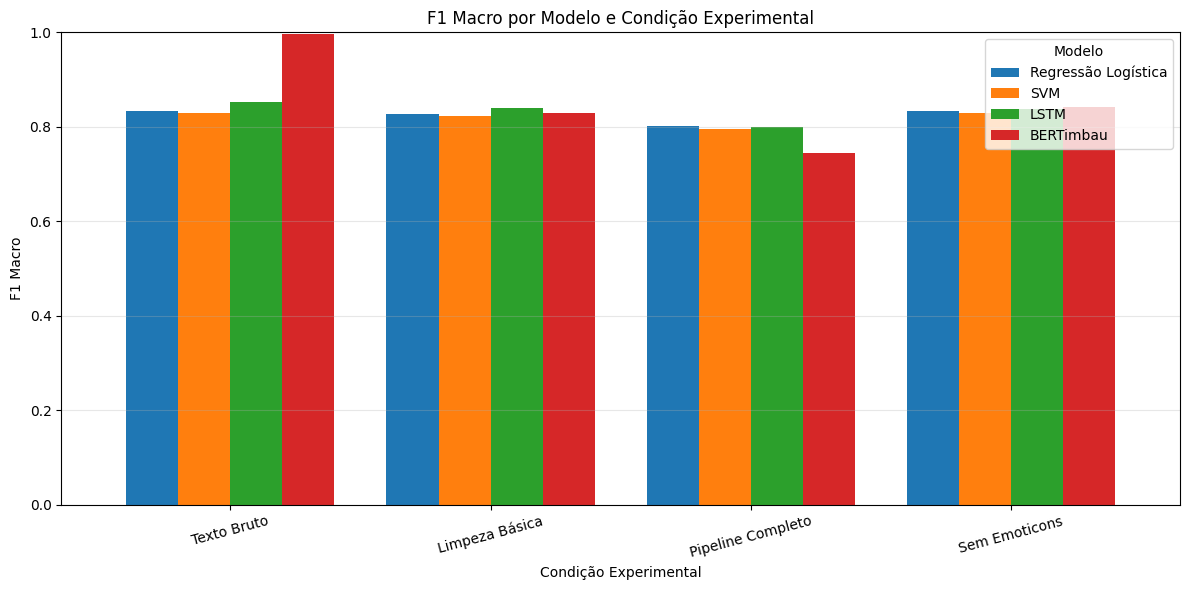


✓ Consolidação concluída.
✓ Resultados e gráfico exportados.
✓ Consolidação salva no Google Drive.


In [1]:


# ============================================================
# 8.1. CONSOLIDAÇÃO DOS RESULTADOS EXPERIMENTAIS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive

# ------------------------------------------------------------
# Recuperação dos resultados definitivos
# ------------------------------------------------------------

drive.mount('/content/drive')

pasta = Path('/content/drive/MyDrive')

arquivos = {
    'Regressão Logística / SVM':
        'resultados_baseline_corrigidos.csv',
    'LSTM':
        'resultados_lstm_corrigidos.csv',
    'BERTimbau':
        'resultados_bert_recuperados.csv'
}

for modelo, nome_arquivo in arquivos.items():
    caminho = pasta / nome_arquivo

    assert caminho.is_file(), (
        f"Arquivo de {modelo} não encontrado: {caminho}"
    )

resultados_baseline_df = pd.read_csv(
    pasta / 'resultados_baseline_corrigidos.csv'
)

resultados_lstm_df = pd.read_csv(
    pasta / 'resultados_lstm_corrigidos.csv'
)

resultados_bert_df = pd.read_csv(
    pasta / 'resultados_bert_recuperados.csv'
)

# ------------------------------------------------------------
# Consolidação dos quatro modelos
# ------------------------------------------------------------

resultados_gerais_df = pd.concat([
    resultados_baseline_df,
    resultados_lstm_df,
    resultados_bert_df
], ignore_index=True)

print("✓ Resultados definitivos carregados do Drive.")


# ------------------------------------------------------------
# Organização e validação
# ------------------------------------------------------------

ordem_modelos = [
    'Regressão Logística',
    'SVM',
    'LSTM',
    'BERTimbau'
]

ordem_condicoes = [
    'Texto Bruto',
    'Limpeza Básica',
    'Pipeline Completo',
    'Sem Emoticons'
]

# Esperamos 4 modelos x 4 condições
combinacoes_esperadas = {
    (modelo, condicao)
    for modelo in ordem_modelos
    for condicao in ordem_condicoes
}

combinacoes_obtidas = list(zip(
    resultados_gerais_df['Modelo'],
    resultados_gerais_df['Condição']
))

assert len(resultados_gerais_df) == 16, (
    "Quantidade incorreta de experimentos."
)

assert len(set(combinacoes_obtidas)) == 16, (
    "Existem combinações duplicadas."
)

assert set(combinacoes_obtidas) == combinacoes_esperadas, (
    "Existem modelos ou condições ausentes."
)

# ------------------------------------------------------------
# Tabela 1 — F1 Macro
# ------------------------------------------------------------

tabela_f1 = resultados_gerais_df.pivot(
    index='Condição',
    columns='Modelo',
    values='F1 Macro'
).reindex(
    index=ordem_condicoes,
    columns=ordem_modelos
)

print("=" * 70)
print("TABELA 1 — F1 MACRO")
print("=" * 70)

display(tabela_f1.round(4))

# ------------------------------------------------------------
# Tabela 2 — Accuracy
# ------------------------------------------------------------

tabela_accuracy = resultados_gerais_df.pivot(
    index='Condição',
    columns='Modelo',
    values='Accuracy'
).reindex(
    index=ordem_condicoes,
    columns=ordem_modelos
)

print("\nTABELA 2 — ACCURACY")
display(tabela_accuracy.round(4))

# ------------------------------------------------------------
# Tabela 3 — Diferença de F1 em relação ao Texto Bruto
# ------------------------------------------------------------

delta_f1 = tabela_f1.subtract(
    tabela_f1.loc['Texto Bruto'],
    axis='columns'
)

print("\nTABELA 3 — VARIAÇÃO DO F1 MACRO")
print("Referência: Texto Bruto")

display(delta_f1.round(4))

# ------------------------------------------------------------
# Gráfico comparativo
# ------------------------------------------------------------

ax = tabela_f1.plot(
    kind='bar',
    figsize=(12, 6),
    rot=15,
    width=0.8
)

ax.set_title(
    'F1 Macro por Modelo e Condição Experimental'
)

ax.set_xlabel('Condição Experimental')
ax.set_ylabel('F1 Macro')
ax.set_ylim(0, 1)
ax.legend(title='Modelo')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig(
    'comparacao_f1_tcc2.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ------------------------------------------------------------
# Exportação
# ------------------------------------------------------------

resultados_gerais_df.to_csv(
    'resultados_gerais_tcc2.csv',
    index=False
)

tabela_f1.to_csv('tabela_f1_tcc2.csv')
tabela_accuracy.to_csv('tabela_accuracy_tcc2.csv')

print("\n✓ Consolidação concluída.")
print("✓ Resultados e gráfico exportados.")


# Salvar os arquivos finais no Google Drive
from pathlib import Path
from shutil import copy2

arquivos_finais = [
    'resultados_gerais_tcc2.csv',
    'tabela_f1_tcc2.csv',
    'tabela_accuracy_tcc2.csv',
    'comparacao_f1_tcc2.png'
]

for nome in arquivos_finais:
    origem = Path(nome)
    assert origem.exists(), f"Arquivo não encontrado: {nome}"
    copy2(origem, pasta / nome)

print("✓ Consolidação salva no Google Drive.")



# 9. Análise Qualitativa dos Erros de Classificação

Esta seção apresenta uma análise qualitativa exploratória dos erros do BERTimbau, complementando a avaliação quantitativa.

A investigação concentra-se na comparação entre **Texto Bruto** e **Sem Emoticons**, buscando compreender como marcadores emocionais e características da linguagem informal podem estar associados às previsões do modelo.

## Procedimento

São utilizadas as contagens de erros recuperadas da execução original do BERTimbau, juntamente com uma amostra intencional de 25 tweets selecionados anteriormente.

A amostra reúne exemplos classificados corretamente em Texto Bruto e incorretamente em Sem Emoticons, contemplando diferentes tipos de confusão entre as classes.

A análise considera a presença de emoticons, ambiguidades, negações, possíveis ironias e dependência de contexto.

As anotações e justificativas são mantidas em um arquivo CSV complementar. Nesta etapa, não são realizadas novas inferências do BERTimbau.

## Discussão dos Resultados

Os exemplos selecionados sugerem que os emoticons podem reforçar sentimentos expressos verbalmente ou fornecer pistas emocionais em mensagens ambíguas.

Também foram observados casos de contraste entre texto e emoticons, além de situações em que mudanças nas previsões ocorreram mesmo sem alteração do conteúdo textual.

Como os modelos foram treinados separadamente em cada condição, essas diferenças não podem ser atribuídas exclusivamente à remoção de emoticons.

Os resultados também devem ser interpretados considerando a associação entre marcadores emocionais e rótulos identificada na auditoria do corpus.

A análise é exploratória, utiliza uma amostra intencional e não permite generalizar a frequência dos fenômenos linguísticos para todo o conjunto de dados. As categorizações propostas permanecem sujeitas à validação humana.


In [2]:

# ============================================================
# 9.1. RESUMO DOS ERROS DO BERTIMBAU
# ============================================================

import pandas as pd

# Recuperar as contagens da execução original
resumo_erros_bert_df = pd.read_csv(
    pasta / 'resumo_erros_bert_recuperados.csv'
)

# Organizar as condições
ordem_condicoes = [
    'Texto Bruto',
    'Limpeza Básica',
    'Pipeline Completo',
    'Sem Emoticons'
]

resumo_erros_bert_df = (
    resumo_erros_bert_df
    .set_index('Condição')
    .loc[ordem_condicoes]
    .reset_index()
)

# Validar as quatro condições e suas contagens
assert len(resumo_erros_bert_df) == 4
assert (resumo_erros_bert_df['Total'] == 1000).all()

assert (
    resumo_erros_bert_df['Erros']
    / resumo_erros_bert_df['Total']
    - resumo_erros_bert_df['Taxa de erro']
).abs().lt(1e-8).all()

# Apresentação
print("ERROS DO BERTIMBAU POR CONDIÇÃO")
print("Fonte: execução experimental anterior")

display(
    resumo_erros_bert_df
)

print(
    "\nObservação: as contagens foram recuperadas "
    "dos resultados históricos, sem novas predições."
)


ERROS DO BERTIMBAU POR CONDIÇÃO
Fonte: execução experimental anterior


,Condição,Erros,Total,Taxa de erro
0,Texto Bruto,3,1000,0.003
1,Limpeza Básica,168,1000,0.168
2,Pipeline Completo,252,1000,0.252
3,Sem Emoticons,157,1000,0.157



Observação: as contagens foram recuperadas dos resultados históricos, sem novas predições.


In [9]:

# ============================================================
# 9.2. AMOSTRA QUALITATIVA CONSOLIDADA
# ============================================================

import pandas as pd

# Carregar a amostra previamente analisada
amostra_qualitativa_df = pd.read_csv(
    pasta / 'analise_qualitativa_revisao_tcc2.csv'
)

# ------------------------------------------------------------
# Validação da amostra
# ------------------------------------------------------------

assert len(amostra_qualitativa_df) == 25

assert amostra_qualitativa_df[
    'indice_teste'
].is_unique

indices = amostra_qualitativa_df['indice_teste']

# Confirmar que os tweets pertencem ao conjunto de teste
assert indices.isin(df_test.index).all()

# Conferir rótulos e textos com o corpus experimental
assert (
    df_test.loc[indices, 'sentiment_enc'].to_numpy()
    == amostra_qualitativa_df['classe_real'].to_numpy()
).all()

assert (
    df_test.loc[indices, 'tweet_text'].to_numpy()
    == amostra_qualitativa_df['texto_original'].to_numpy()
).all()

# Confirmar as condições de seleção da amostra
assert (
    amostra_qualitativa_df['previsao_texto_bruto']
    == amostra_qualitativa_df['classe_real']
).all()

assert (
    amostra_qualitativa_df['previsao_sem_emoticons']
    != amostra_qualitativa_df['classe_real']
).all()

# ------------------------------------------------------------
# Distribuição da amostra
# ------------------------------------------------------------

print("AMOSTRA QUALITATIVA — 25 TWEETS")

print("\nTipos de confusão:")
display(
    amostra_qualitativa_df[
        'transicao'
    ].value_counts()
)

# ------------------------------------------------------------
# Cinco exemplos representativos
# ------------------------------------------------------------

exemplos_destaque = amostra_qualitativa_df[
    amostra_qualitativa_df['destaque_relatorio']
    .str.strip()
    .str.lower()
    .eq('sim')
].copy()

assert len(exemplos_destaque) == 5

print("\nEXEMPLOS REPRESENTATIVOS:")

with pd.option_context('display.max_colwidth', None):
    display(
        exemplos_destaque[
            [
                'indice_teste',
                'transicao',
                'texto_original',
                'categoria_sugerida',
                'justificativa_proposta'
            ]
        ]
    )

print("\n✓ Amostra qualitativa validada.")
print("✓ Categorizações pendentes de validação humana.")


AMOSTRA QUALITATIVA — 25 TWEETS

Tipos de confusão:


,count
transicao,
1 → 0,9
0 → 1,8
1 → 2,6
0 → 2,1
2 → 1,1



EXEMPLOS REPRESENTATIVOS:


,indice_teste,transicao,texto_original,categoria_sugerida,justificativa_proposta
5,60533,0 → 1,encontrei a camisola mais gira dos Beatles mas só encontrei em S e tipo :((((,Emoticons e marcadores gráficos,O contraste entre gostar da camisola e encontrá-la apenas no tamanho S é reforçado por “:((((”.
8,56490,0 → 2,As fotos são do dia 08/09 durante o Korean Music Festival! As meninas performaram “Into The New World” do SNSD e “Dreams Come True”! Eunseo não participou do cover de SNSD :( Into The New World » https://t.co/swaj8COmp8 Dreams Come True » https://t.co/8RfiFe3IsF https://t.co/XoLtI9isrp,Emoticons e marcadores gráficos,A informação factual sobre o festival inclui a ausência de Eunseo; “:(” sinaliza pesar. A data foi preservada.
11,23914,1 → 0,"To muito triste com meu bolo, ele ficou ótimo Só tá com gosto de sal :)",Contraste de polaridade e possível ironia,"“muito triste”, “ficou ótimo” e “gosto de sal” coexistem; o emoticon “:)” pode ser irônico ou sinalizar humor. O rótulo positivo merece análise, sem concluir que está incorreto."
18,1261,1 → 2,Vagas pro Mestrado/Doc em Eng. dos Materiais aqui na USP-São Carlos :) https://t.co/j9eTRFhaHj,Emoticons e marcadores gráficos,O conteúdo sobre vagas é essencialmente informativo; “:)” acrescenta positividade.
24,81162,2 → 1,Vai começar a pancadaria sobre Haddad https://t.co/y5a6kyEStF -via @brdezoito,Contexto externo,"O texto é idêntico nas duas condições, mas a predição difere. Isso é compatível com diferenças aprendidas por modelos treinados separadamente, não com uma remoção local de emoticon."



✓ Amostra qualitativa validada.
✓ Categorizações pendentes de validação humana.
